In [22]:
import pandas as pd
import numpy as np
import h5py
import re

from sklearn.neighbors import NearestNeighbors
from scipy.stats import wilcoxon

import matplotlib.pyplot as plt

In [11]:
def nearest_other_anchor(X, metric):
    """Index of each row's nearest *other* row in X."""
    nn = NearestNeighbors(n_neighbors=2, metric=metric, algorithm="brute").fit(X)
    dist, idx = nn.kneighbors(X)
    self_idx = np.arange(len(X))[:, None]
    pick = (idx != self_idx).argmax(axis=1)
    rows = np.arange(len(X))
    return idx[rows, pick], dist[rows, pick]

def anchor_neighbors(anchors, id_col="Entry", 
                     umap_cols=("UMAP 1", "UMAP 2"), emb_col="embedding"):

    X_umap = anchors[list(umap_cols)].to_numpy()
    X_emb = np.vstack(anchors[emb_col].to_numpy())

    u_idx, u_dist = nearest_other_anchor(X_umap, "euclidean")
    c_idx, c_dist = nearest_other_anchor(X_emb, "cosine")

    ids = anchors[id_col].to_numpy()
    out = pd.DataFrame({
        "anchor": ids,
        "umap_neighbor": ids[u_idx],
        "cosine_neighbor": ids[c_idx],
        "umap_dist": u_dist,
        "cosine_dist": c_dist,
    })
    out["same_neighbor"] = out["umap_neighbor"] == out["cosine_neighbor"]
    return out

def dataset_analysis(analysis):
    directory = '/uss/jespinozaherrera/ms_work/1.plvis_testing/3.clustering/kmeans/'

    df = pd.read_csv(f'{directory}{analysis}_prott5_umap_kmeans.csv')
    anchors = df[df['Annotation'] == 5].reset_index(drop=True)
    directory = '/uss/jespinozaherrera/ms_work/1.plvis_testing/1.embeddings_and_df/'

    with h5py.File(f'{directory}{analysis}_prott5.h5', "r") as f:
        emb_dict = {key: f[key][:] for key in f.keys()}

    anchors["embedding"] = anchors["Entry"].astype(str).map(emb_dict)
    
    res = anchor_neighbors(anchors)
    res_list = pd.concat([res['anchor'], res['umap_neighbor'], res['cosine_neighbor']]).unique().tolist()
    print(analysis)
    print(res["same_neighbor"].mean())
    return df, res, res_list

mtb_df, mtb_res, mtb_list = dataset_analysis('mtb')
sterol_df, sterol_res, sterol_list = dataset_analysis('sterol')
myc_df, myc_res, myc_list = dataset_analysis('mycobacterium')
plas_df, plas_res, plas_list = dataset_analysis('plasmodium')

mtb
0.3184713375796178
sterol
0.2035863068284731
mycobacterium
0.4103019538188277
plasmodium
0.3389830508474576


In [20]:
def parse_ipr(s):
    return set(re.findall(r"IPR\d{6}", s)) if pd.notna(s) else set()

def parse_go(s):
    return set(re.findall(r"GO:\d{7}", s)) if pd.notna(s) else set()

def parse_ec(s):
    """Set of EC numbers truncated to 3 levels; drops incomplete ones like 2.7.-.-"""
    if pd.isna(s):
        return set()
    out = set()
    for ec in re.findall(r"\d+\.[\d\-]+\.[\d\-]+(?:\.[\d\-n]+)?", str(s)):
        parts = ec.split(".")[:3]
        if "-" not in parts:
            out.add(".".join(parts))
    return out

def jaccard(a, b):
    if not a or not b:
        return np.nan          # no annotation on one side: unscorable, not zero
    return len(a & b) / len(a | b)

def ec_match(a, b):
    if not a or not b:
        return np.nan
    return float(len(a & b) > 0)

def score_transfers(res, ann, id_col="Entry",
                    ipr_col="InterPro", go_col="Gene Ontology (GO)", ec_col="EC number"):
    ann = ann.drop_duplicates(id_col).set_index(id_col)   # duplicate IDs also raise errors
    ipr = ann[ipr_col].map(parse_ipr).to_dict()
    go  = ann[go_col].map(parse_go).to_dict()
    ec  = ann[ec_col].map(parse_ec).to_dict()
    empty = set()

    # report how many anchors/neighbors have no row in the annotation table
    ids = set(res["anchor"]) | set(res["umap_neighbor"]) | set(res["cosine_neighbor"])
    missing = ids - set(ann.index)
    print(f"{len(missing)} of {len(ids)} accessions not in annotation table")

    out = res.copy()
    for space in ("umap", "cosine"):
        nb = out[f"{space}_neighbor"]
        out[f"ipr_{space}"] = [jaccard(ipr.get(a, empty), ipr.get(b, empty)) for a, b in zip(out["anchor"], nb)]
        out[f"go_{space}"]  = [jaccard(go.get(a, empty),  go.get(b, empty))  for a, b in zip(out["anchor"], nb)]
        out[f"ec_{space}"]  = [ec_match(ec.get(a, empty), ec.get(b, empty))  for a, b in zip(out["anchor"], nb)]

    for m in ("ipr", "go", "ec"):
        out[f"{m}_diff"] = out[f"{m}_cosine"] - out[f"{m}_umap"]   # >0 means native is better
    return out

def dataset_scoring(res, df_ann):
    scored = score_transfers(res, df_ann)
    disc = scored[~scored["same_neighbor"]]
    print(disc[["ipr_diff", "go_diff", "ec_diff"]].describe())
    print(disc[["ipr_umap","ipr_cosine"]].mean())
    return scored

mtb_data = pd.read_csv('mtb_data.tsv', sep='\t')
sterol_data = pd.read_csv('sterol_data.tsv', sep='\t')
myc_data = pd.read_csv('mycobacterium_data.tsv', sep='\t')
plas_data = pd.read_csv('plasmodium_data.tsv', sep='\t')

mtb_scored = dataset_scoring(mtb_res, mtb_data)
sterol_scored = dataset_scoring(sterol_res, sterol_data)
myc_scored = dataset_scoring(myc_res, myc_data)
plas_scored = dataset_scoring(plas_res, plas_data)

0 of 471 accessions not in annotation table
         ipr_diff     go_diff     ec_diff
count  318.000000  318.000000  233.000000
mean     0.094394    0.066173    0.137339
std      0.295291    0.199215    0.443367
min     -0.785714   -0.603175   -1.000000
25%      0.000000   -0.017708    0.000000
50%      0.000000    0.004381    0.000000
75%      0.123162    0.111111    0.000000
max      1.000000    0.805556    1.000000
ipr_umap      0.135895
ipr_cosine    0.228849
dtype: float64
4 of 5521 accessions not in annotation table
          ipr_diff      go_diff      ec_diff
count  2991.000000  2991.000000  2369.000000
mean      0.034187     0.071078     0.010131
std       0.135987     0.294150     0.115805
min      -1.000000    -0.975309    -1.000000
25%       0.000000     0.000000     0.000000
50%       0.000000     0.000000     0.000000
75%       0.000000     0.130435     0.000000
max       1.000000     1.000000     1.000000
ipr_umap      0.935360
ipr_cosine    0.966705
dtype: float64
0 of 5

In [23]:
def summarize(scored, metrics=("ipr", "go", "ec"), n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    disc = scored[~scored["same_neighbor"]]
    rows = []
    for m in metrics:
        d = disc[f"{m}_diff"].dropna().to_numpy()
        boots = rng.choice(d, size=(n_boot, len(d)), replace=True).mean(axis=1)
        nz = d[d != 0]
        p = wilcoxon(nz).pvalue if len(nz) > 0 else np.nan
        rows.append({
            "metric": m,
            "n_scorable": len(d),
            "native_wins": int((d > 0).sum()),
            "umap_wins": int((d < 0).sum()),
            "ties": int((d == 0).sum()),
            "mean_diff": d.mean(),
            "ci_low": np.percentile(boots, 2.5),
            "ci_high": np.percentile(boots, 97.5),
            "wilcoxon_p": p,
        })
    return pd.DataFrame(rows)

s_mtb = summarize(mtb_scored) 
s_sterol = summarize(sterol_scored)
s_myc = summarize(myc_scored) 
s_plas = summarize(plas_scored)

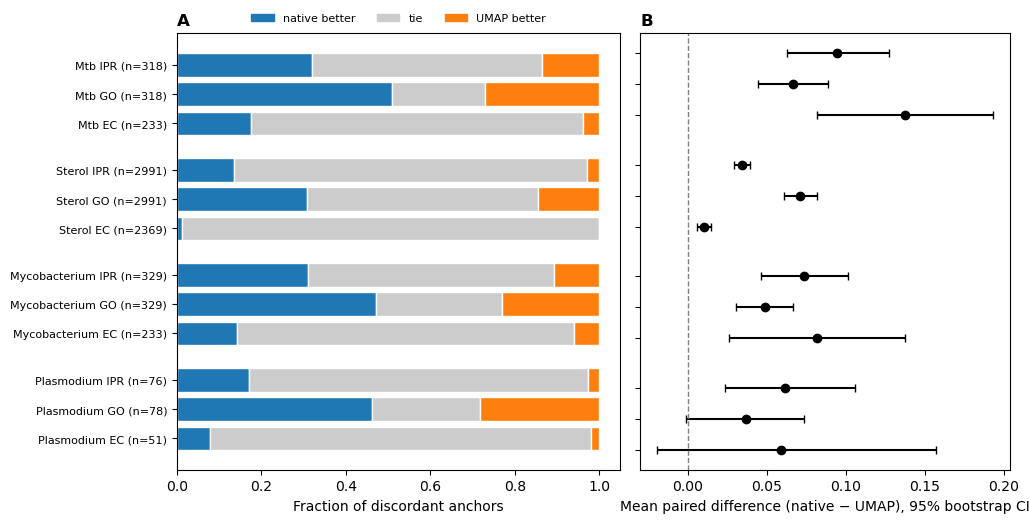

In [26]:
def boot_ci(x, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    boots = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.percentile(boots, [2.5, 97.5])

def make_figure(summaries, fname="anchor_transfer.png"):
    native_c, umap_c, tie_c = "C0", "C1", "#cccccc"

    # one row per (dataset, metric), with a gap between datasets
    ypos, labels, rows, y = [], [], [], 0
    for ds, s in summaries.items():
        for _, r in s.iterrows():
            ypos.append(y); rows.append(r)
            labels.append(f"{ds} {r['metric'].upper()} (n={r['n_scorable']})")
            y += 1
        y += 0.6

    ncols = 2
    fig, axes = plt.subplots(1, ncols, figsize=(5.2 * ncols, max(4, 0.32 * len(ypos) + 1.5)),
                             gridspec_kw={"width_ratios": [1.2, 1, 1.1][:ncols]})

    # Panel A: win / tie / loss composition
    ax = axes[0]
    for yy, r in zip(ypos, rows):
        n, left = r["n_scorable"], 0
        for v, c in zip([r["native_wins"], r["ties"], r["umap_wins"]],
                        [native_c, tie_c, umap_c]):
            ax.barh(yy, v / n, left=left, color=c, edgecolor="white")
            left += v / n
    ax.set_yticks(ypos); ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Fraction of discordant anchors")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (native_c, tie_c, umap_c)],
              labels=["native better", "tie", "UMAP better"], frameon=False,
              fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
    ax.set_title("A", loc="left", fontweight="bold")

    # Panel B: paired mean difference with bootstrap CI
    ax = axes[1]
    for yy, r in zip(ypos, rows):
        ax.errorbar(r["mean_diff"], yy,
                    xerr=[[r["mean_diff"] - r["ci_low"]], [r["ci_high"] - r["mean_diff"]]],
                    fmt="o", color="k", capsize=3)
    ax.axvline(0, color="grey", ls="--", lw=1)
    ax.set_yticks(ypos); ax.set_yticklabels([])
    ax.invert_yaxis()
    ax.set_xlabel("Mean paired difference (native − UMAP), 95% bootstrap CI")
    ax.set_title("B", loc="left", fontweight="bold")

    fig.tight_layout()
    #fig.savefig(fname, dpi=300)

make_figure({"Mtb": s_mtb, "Sterol": s_sterol, "Mycobacterium": s_myc, "Plasmodium": s_plas})